In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers
import os

import tensorflow_datasets as tfds
dataset_name = 'cats_vs_dogs'
dataset, info = tfds.load(name=dataset_name, with_info=True, as_supervised=True)

train_data = dataset["train"].take(20000) #take 20000 images for training
val_data = dataset["train"].skip(20000).take(5000) #skip the first 20000 images and take the
#  next 5000 images for validation

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.C406ZP_4.0.1/cats_vs_dogs-train.tfrecord*...:   0%…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.


In [ ]:
#Preprocessing images
IMG_SIZE = 128  # Resize images to 128x128 pixels

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))  # Resize image
    image = image / 255.0  # Normalize pixel values
    return image, label

# Apply preprocessing to training and validation sets
train_data = train_data.map(preprocess).batch(32).shuffle(1000)
val_data = val_data.map(preprocess).batch(32)

In [ ]:

model = keras.Sequential([
    # First Convolutional Layer
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(2, 2),

    # Second Convolutional Layer
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Third Convolutional Layer
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Flattening Layer
    layers.Flatten(),

    # Fully Connected Layer
    layers.Dense(512, activation="relu"),

    # Output Layer (Binary Classification)
    layers.Dense(1, activation="sigmoid")
])

# Compile the model
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Display model summary
model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,329 (49.36 MB)

 Trainable params: 12,939,329 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Step 5: Train the model
history = model.fit(train_data, epochs=10, validation_data=val_data)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 48ms/step - accuracy: 0.6062 - loss: 0.6724 - val_accuracy: 0.7005 - val_loss: 0.5679
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 76s 49ms/step - accuracy: 0.7564 - loss: 0.5033 - val_accuracy: 0.7949 - val_loss: 0.4470
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 49ms/step - accuracy: 0.8130 - loss: 0.4029 - val_accuracy: 0.8148 - val_loss: 0.4134
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 80s 45ms/step - accuracy: 0.8546 - loss: 0.3306 - val_accuracy: 0.8265 - val_loss: 0.3899
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 49ms/step - accuracy: 0.8990 - loss: 0.2404 - val_accuracy: 0.8105 - val_loss: 0.4816
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 49ms/step - accuracy: 0.9418 - loss: 0.1496 - val_accuracy: 0.8274 - val_loss: 0.4792
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 50ms/step - accuracy: 0.9746 - loss: 0.0732 - val_accuracy: 0.8277 - val_loss: 0.6049
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 47s 46ms/step - accuracy: 0.9856 - loss: 0.0443 - 

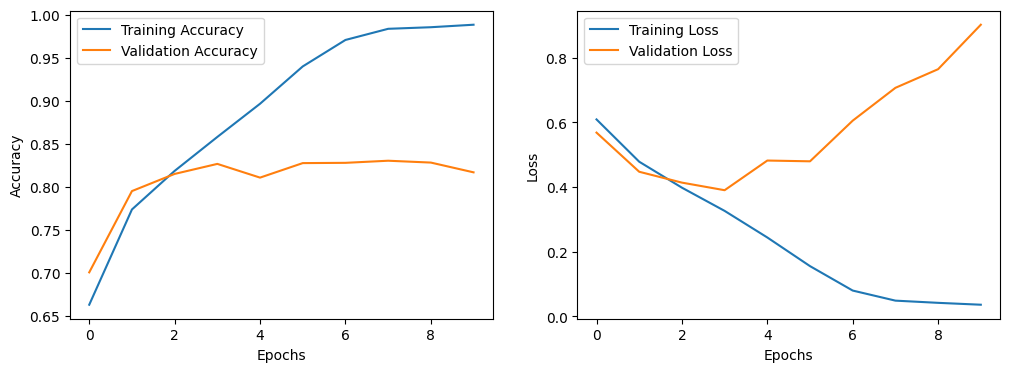

In [ ]:
#Step 6: plot training performance
plt.figure(figsize=(12, 4))

#accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

#loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


Saving dog1.jpeg to dog1.jpeg


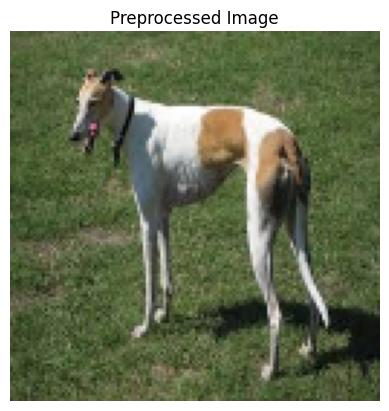

In [ ]:
# Step 1: Import required libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 2: Upload image (simpler and safer than hardcoding path)
from google.colab import files
uploaded = files.upload()

# Step 3: Get uploaded image name
img_path = list(uploaded.keys())[0]

# Step 4: Load and preprocess the image
image = cv2.imread(img_path)                      # Read image
image = cv2.resize(image, (128, 128))             # Resize to match model input
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)    # Convert BGR to RGB
image = image / 255.0                             # Normalize pixel values (0–1)
image = np.expand_dims(image, axis=0)             # Add batch dimension

# Step 5: Show the image
plt.imshow(image[0])
plt.title("Preprocessed Image")
plt.axis("off")
plt.show()


In [ ]:
# Predict the class using the trained model
prediction = model.predict(image)

# prediction is an array like [[0.92]], so we take the first value
predicted_value = prediction[0][0]

# Print the probability
print(f"Model confidence: {predicted_value:.2f}")

# Make decision based on threshold (0.5)
if predicted_value > 0.5:
    print("The model predicts: Dog 🐶")
else:
    print("The model predicts: Cat 🐱")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Model confidence: 1.00
The model predicts: Dog 🐶
